## Initial Spinup Analysis: 
Comparison of model output to forcing to ensure everything is working as expected.

Notes on Julian vs Gregorian dates:
The model runs on a Julian calendar, meaning that any year divisible by 4 is a leap year. In contrast, the Gregorian calendar is similar but skips certain leap years (divisible by 100 but not 400). The most relevant date is 1900 for spinup, which is a leap year in the Julian calendar but not in the Gregorian calendar. When comparing to forcing, I need to keep this in mind.

Plotting and resampling all depend on normal datetime indicies, so I am going to convert the Julian dates to Gregorian. The land_daily data is most problematic since it typically includes 1900. I will simply switch out the calendar for the output by creating a new index that starts at the same time but uses the Gregorian calendar.

In [1]:
%matplotlib ipympl
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd
import os

In [2]:
# Run configuration
snotel_site = 'Trial Lake'  #Use the Snotel name
spin_up = '50y'
forcings = 's00000000'
forcing_version = 'v0.4.4'  # Version of the forcing data
spinup_version = 'v0.4debug2'
path_env = 'desktop' # 'desktop' or 'alpine'

In [3]:
# Configure environment
if path_env == 'desktop':
    output_path = 'C:/Users/clmbn/NMT_PhD/data/output' #desktop
    snotel_path = 'C:/Users/clmbn/NMT_PhD/data/snotel/' #desktop
    forcing_path = 'C:/Users/clmbn/NMT_PhD/data/forcing/' #desktop
elif path_env == 'alpine':
    output_path = r'/projects/ccox1@xsede.org/lm4px_modelling/output' #Alpine
    snotel_path = r'/projects/ccox1@xsede.org/data/snotel/'
    forcing_path = r'/projects/ccox1@xsede.org/data/forcing/'
else:
    raise ValueError("Invalid path_env. Choose 'desktop' or 'alpine'.")

In [4]:
# Convert name for output paths
site = snotel_site.replace(' ','').lower()
print(f'Output site: {site}')

Output site: triallake


Load forcing:
Forcing is 10 years of NLDAS data that is then looped for the spinup period.

In [5]:
forcing_10yr = xr.open_dataset(os.path.join(forcing_path, site, f'{site}_spinup_s00000000_{forcing_version}.nc'))

In [ ]:
forcing_10yr

In [ ]:
# Check on a few forcing variables
forcing_check = forcing_10yr[['SWdown','Tair','Psurf']].isel(latitude=0, longitude=0).to_dataframe()
forcing_check = forcing_check[:'1981-01-01']

In [ ]:
SWdown_short = SWdown['1980-12-31':'1981-01-01']

In [6]:
def get_spinup_forcing(forcing_ds: xr.Dataset, var_name: str) -> pd.Series:
    '''
    Extract a given variable (at a daily timestep) from the forcing dataset and loop it for the 100 year spinup period.
    Return a pandas Series with the looped data.
    '''
    # If 'precip' get sum of 'Rainf' and 'Snowf'
    if var_name == 'precip':
        forcing_ds = forcing_ds.assign(precip=forcing_ds['Rainf'] + forcing_ds['Snowf'])
    
    # Extract the variable data
    var_df = forcing_ds[var_name].isel(latitude=0, longitude=0).to_dataframe()
    data = var_df[var_name] # Extract the variable column
    data.index = data.index.to_datetimeindex()  # This will give a warning but shouldn't be problematic since the spinup forcing is > 1900

    # Resample to daily frequency
    data_daily = data.resample('D').mean()

    # Loop the data for the spinup period
    spinup_years = int(spin_up[:-1])  # Extract the number of years from the spin_up string
    model_start_year = data_daily.index[-1].year - spinup_years
    model_start = data_daily.index[0].replace(year=model_start_year)

    # Create date range accounting for Julian 1900 leap year if necessary
    if model_start < pd.Timestamp('1900-03-01'):
        model_end = data_daily.index[-1] + pd.Timedelta(days=1)  # Add on a day to account for the leap year in 1900
    else:
        model_end = data_daily.index[-1]
    model_index = pd.date_range(start=model_start, end=model_end, freq='D')

    # Loop the data to fill the spinup period, using 1 extra concatenation to ensure full coverage
    looped = pd.concat([data_daily] * int(spinup_years / 10 + 1), ignore_index=True)
    
    # Ensure the looped data matches the model index length
    looped_values = looped[:len(model_index)].values

    # Shift index by 12 hours to match model output
    model_index = model_index + pd.Timedelta(hours=12)

    output = pd.Series(looped_values, index=model_index)
    output.name = var_name

    return output
    


In [ ]:
# Verify the function works for Tair
# test = get_spinup_forcing(forcing_10yr, 'Tair')
# test2 = forcing_10yr['Tair'].isel(latitude=0, longitude=0).to_series()
# test2.index = test2.index.to_datetimeindex()  # This will give a warning but shouldn't be problematic since the spinup forcing is > 1900
# test2 = test2.resample('D').mean()

Load diagnostics

In [7]:
output_folder = os.path.join(output_path,f'{site}/{site}_spinup_{spin_up}_{forcings}_{spinup_version}/history/')

In [8]:
# Find the land daily file name in folder and open
land_daily=None
for filename in os.listdir(output_folder):
    if filename.endswith(".land_daily.nc"):
        land_daily = xr.open_dataset(output_folder + filename)
if not land_daily:
    print('Error: no land daily found')

c:\Users\clmbn\NMT_PhD\lm4px_data_analysis\.env312\Lib\site-packages\xarray\coding\times.py:1005: SerializationWarning: Unable to decode time axis into full numpy.datetime64 objects, continuing using cftime.datetime objects instead, reason: dates out of range
  dtype = _decode_cf_datetime_dtype(data, units, calendar, self.use_cftime)


In [ ]:
# Create a dataframe whose index is the name of the variable and the columns are: dimensions, long_name, units
daily_vars_df = pd.DataFrame({
    'dimensions': [land_daily[var].dims for var in land_daily.data_vars],
    'long_name': [land_daily[var].attrs.get('long_name', '') for var in land_daily.data_vars],
    'units': [land_daily[var].attrs.get('units', '') for var in land_daily.data_vars]
}, index=land_daily.data_vars)

In [9]:
land_daily

<xarray.Dataset> Size: 3MB
Dimensions:                  (grid_index: 1, time: 7305, nv: 2, lon: 1,
                              lonb: 2, lat: 1, latb: 2, zfull_soil: 20,
                              zhalf_soil: 21, band: 2)
Coordinates:
  * grid_index               (grid_index) float64 8B 0.0
  * time                     (time) object 58kB 0001-01-01 12:00:00 ... 0020-...
  * nv                       (nv) float64 16B 1.0 2.0
  * lon                      (lon) float64 8B -111.0
  * lonb                     (lonb) float64 16B -111.5 -110.5
  * lat                      (lat) float64 8B 40.68
  * latb                     (latb) float64 16B 40.18 41.18
  * zfull_soil               (zfull_soil) float64 160B 0.01 0.04 ... 6.75 8.75
  * zhalf_soil               (zhalf_soil) float64 168B 0.0 0.02 ... 7.5 10.0
  * band                     (band) float64 16B 1.0 2.0
    geolon_t                 (grid_index) float64 8B ...
    geolat_t                 (grid_index) float64 8B ...
Data variables: (12/56)
    fco2                     (time, grid_index) float32 29kB ...
    t_ref                    (time, grid_index) float32 29kB ...
    co2_mol_flux             (time, grid_index) float32 29kB ...
    co2_mol_flux1            (time, grid_index) float32 29kB ...
    btot                     (time, grid_index) float32 29kB ...
    Ctot                     (time, grid_index) float32 29kB ...
    ...                       ...
    drydep_md                (time, grid_index) float32 29kB ...
    drydep_om                (time, grid_index) float32 29kB ...
    average_T1               (time) object 58kB ...
    average_T2               (time) object 58kB ...
    average_DT               (time) timedelta64[ns] 58kB ...
    time_bnds                (time, nv) object 117kB ...
Attributes:
    filename:          land_daily.nc
    title:             
    associated_files:  soil_area: land_static.nc land_area: land_static.nc
    grid_type:         regular
    grid_tile:         N/A

#### Calendar conversion:
Create a new calendar index that is gregorian starting at the same time as the output.

In [ ]:
# Get the first time coordinate from the daily dataset
model_start_str = land_daily['time'].to_index()[0].strftime('%Y-%m-%d 12:00')
model_end_str = land_daily['time'].to_index()[-1].strftime('%Y-%m-%d 12:00')
model_start = pd.Timestamp(model_start_str)

# Create a date range for the model index
# Adjust the end date to account for the leap year in 1900
if model_start < pd.Timestamp('1900-03-01'):
    model_end = pd.Timestamp(model_end_str) + pd.Timedelta(days=1)  # Add on a day to account for the leap year in 1900
else:
    model_end = pd.Timestamp(model_end_str) 

output_index_gregorian = pd.date_range(start=model_start, end=model_end, freq='D')

In [ ]:
# Generate some variables for plotting
plot_start_date = model_start.strftime('%Y-%m-%d 12:00')
plot_end_date = model_start.replace(year=model_start.year + 10).strftime('%Y-%m-%d 12:00')

### Analysis: Temperature
In the daily output, it appears that air temperature and shortwave radiation are the only variables that are directly comparible to the forcing data. Even so, t_ref is 2m air temperature, while the forcing is set to 10m. The shortwave radiation is also partitioned by the model into direct and diffuse components, while the forcing is total shortwave radiation.

Even so, I can make a number of comparisons to see if there is consistency.

In [10]:
model_surface_data = land_daily[['t_ref', 'snow_frac', 'snow_depth', 'Tgrnd']].isel(grid_index=0).to_dataframe()
#model_surface_data.index = output_index_gregorian
model_surface_data = model_surface_data[['t_ref', 'snow_frac', 'snow_depth', 'Tgrnd']]  #Just get the variables of interest

In [ ]:
# Get the forcing Tair
Tair = get_spinup_forcing(forcing_10yr, 'Tair')

In [ ]:
# Plot just the first 20 years of the Tair forcing and t_ref
fig, ax = plt.subplots(figsize=(12, 6))
Tair[plot_start_date:plot_end_date].plot(ax=ax, label='Tair forcing', color='blue')
model_surface_data.loc[plot_start_date:plot_end_date, ['t_ref','Tgrnd']].plot(ax=ax, label='t_ref')
ax.set_title(f'{snotel_site} - 10 year spinup comparison starting 1986')
ax.set_ylabel('Temperature (K)')


### Analysis: Radiation
The model partitions incoming shortwave radiation into direct and diffuse components, as well as, two bands (VIS, NIR). The forcing data provides total shortwave radiation. To compare, I will sum all model radiation components and compare to the forcing data.

In [11]:
# Extract SW radiation components from land_daily
swdn_dir = land_daily['swdn_dir'].isel(grid_index=0).to_dataframe()
swdn_dir = swdn_dir.reset_index().pivot(index='time', columns='band', values='swdn_dir')

swdn_diff = land_daily['swdn_dif'].isel(grid_index=0).to_dataframe()
swdn_diff = swdn_diff.reset_index().pivot(index='time', columns='band', values='swdn_dif')

# Combine the direct and diffuse components
swdn_combined = pd.merge(swdn_dir, swdn_diff, left_index=True, right_index=True, suffixes=('_dir', '_dif'))

# Test
swdn_combined.head()

band,1.0_dir,2.0_dir,1.0_dif,2.0_dif
time,,,,
0001-01-01 12:00:00,11.477423,15.214257,7.034549,9.324867
0001-01-02 12:00:00,11.384327,15.090852,6.977491,9.249232
0001-01-03 12:00:00,11.303064,14.983131,6.927684,9.183209
0001-01-04 12:00:00,11.938988,15.826100,7.317444,9.699867
0001-01-05 12:00:00,11.707410,15.519124,7.175509,9.511722


In [12]:
swdn_combined['swdn_total'] = swdn_combined.sum(axis=1)

In [ ]:
swdn_combined.index = output_index_gregorian

In [13]:
SWdown = get_spinup_forcing(forcing_10yr, 'SWdown')

AttributeError: 'DatetimeIndex' object has no attribute 'to_datetimeindex'

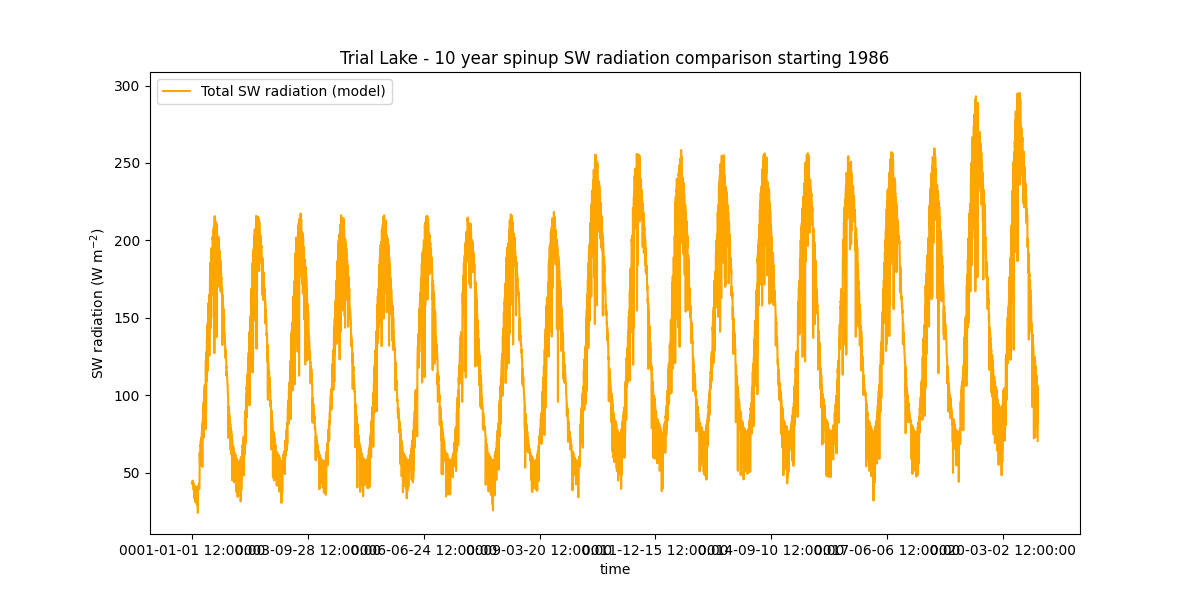

In [16]:
# Plot the SW radiation components
fig, ax = plt.subplots(figsize=(12, 6))
swdn_combined.loc[:,'swdn_total'].plot(ax=ax, color='orange', label='Total SW radiation (model)')
#SWdown[plot_start_date:plot_end_date].plot(ax=ax, color='red', label='SWdown forcing')
ax.set_title(f'{snotel_site} - 10 year spinup SW radiation comparison starting 1986')
ax.set_ylabel('SW radiation (W m$^{-2}$)')
# Add legend
ax.legend()

### Analysis: Snow

In [ ]:
# Plot snow and snow fraction in subplots
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
model_surface_data.loc[plot_start_date:plot_end_date,'snow_depth'].plot(ax=ax1, label='Snow Depth', color='blue')
model_surface_data.loc[plot_start_date:plot_end_date,'snow_frac'].plot(ax=ax2, label='Snow Fraction', color='black')